💳 Paisabazaar Credit Score Analysis

**Project type:** Exploratory Data Analysis (EDA) + Credit Score Classification

## Business Problem
Paisabazaar helps customers find and apply for loans and credit cards. Judging how
trustworthy a customer is (their credit score) is key for loan approval and risk control.
This notebook explores customer data to understand what drives a Poor, Standard or Good
credit score, and builds a simple model to predict it.

## Notebook Roadmap
1. Know your data
2. Missing values and cleaning
3. Insights and correlations
4. Visualizations
5. Hypothesis testing and model
6. Conclusion


## Problem Statement

Paisabazaar helps customers find and apply for banking and credit products. To approve loans safely, it must judge how likely a customer is to repay. The credit score is the main signal for this, but checking each customer by hand is slow and can be inconsistent.

**Goal:** Build a model that predicts a customer's credit score class (**Poor, Standard or Good**) from details such as income, credit card use and payment behaviour.

**Milestones we completed:**
1. Explore the data: head, tail, summary and a data dictionary.
2. Find and handle missing values, including the hidden ones ("NM" and "No Data").
3. Clean the data and find trends and correlations.
4. Present the findings with 10 different pastel charts.
5. Test three hypotheses statistically.
6. Prepare the features and split the data by customer.
7. Compare three models, tune the best two, and test the final model on unseen customers.
8. Explain the model (feature importance) and state the business impact.
9. Save the model for future use.

**Success measure:** Catch as many risky (Poor) customers as possible while keeping a good balance across all 3 classes. So we judge the model by **macro F1 and Poor recall**, not accuracy alone.

## Project Summary

**Business context.** Paisabazaar helps customers find and apply for loans and credit cards. Judging how trustworthy a customer is, which is shown by the credit score, is central to loan approval and risk control. This project studies customer data and builds a model that predicts whether a customer's credit score is Poor, Standard or Good.

**Data.** The dataset has 100,000 rows and 28 columns. It covers 12,500 customers, each observed for 8 months. There are no NaN values and no duplicate rows. However, missing data was hidden inside text, such as "NM" in Payment_of_Min_Amount and "No Data" in Type_of_Loan, and some records had under-18 ages. We explored the data using head, tail, summary statistics and a data dictionary, then cleaned it step by step.

**Exploration.** We made 10 pastel charts of different types: donut, box plots, stacked bars, bar charts, a correlation heatmap, a line chart, a scatter plot, violin plots, a grouped bar chart and a feature importance chart. Key findings: 53% of records are Standard, 29% are Poor and only 18% are Good, so the classes are imbalanced. Under-18 customers are 45% Poor, ages 18 to 45 are about 31%, and ages 46 and above are only 12.6%. Occupation barely matters. Payment delay, interest rate, outstanding debt and credit mix separate the classes clearly.

**Hypothesis tests.** We ran three tests at a 0.05 significance level. Payment delay differs across the score classes (Kruskal-Wallis, large effect). Credit mix is linked to credit score (Chi-square, Cramer's V = 0.45). Poor customers pay higher interest rates (Mann-Whitney U). All three statements were supported. Because each customer appears 8 times, the p-values are slightly optimistic, so we also reported effect sizes.

**Modelling.** We removed identifiers, turned Type_of_Loan into 9 simple loan flags, encoded the text columns and kept outliers because they are real values. We split the data 80/20 by customer, so the 8 months of one customer never appear in both train and test. We compared Logistic Regression, Random Forest and Gradient Boosting using 3-fold cross-validation split by customer, with balanced class weights. We then tuned the two tree models with Randomized Search, scoring on macro F1. After tuning, the cross-validation macro F1 was 67.9% for Random Forest and 68.2% for Gradient Boosting.

**Final result.** On 20,000 unseen test rows (2,500 customers), the final model, **Gradient Boosting**, reached **68.7% accuracy, 68.1% macro F1 and 76.3% Poor recall**. The baseline Logistic Regression reached 65.0% macro F1 and 67.2% Poor recall. Random Forest caught slightly more Poor customers (78.1%) but had lower macro F1 (67.2%) and accuracy (67.7%), so we chose Gradient Boosting as the best overall balance. We judged the models by macro F1 and Poor recall, not accuracy alone, because missing a risky customer costs more than turning away a safe one. The main drivers are **Credit_Mix, Interest_Rate and Delay_from_due_date**, followed by Outstanding_Debt and Credit_History_Age.

**Business value and limits.** Paisabazaar can use the model to pre-screen applicants, send borderline cases to manual review, and give customers simple advice such as paying on time. The model should support loan officers, not replace them. About 11% of Poor customers are still wrongly called Good, and only about 53% of customers called Good really are Good. Other limits include only 8 rows per customer, under-18 records, hidden missing values and scores that change from month to month. The final model is saved with joblib and can be reloaded to predict on new customers.

In [66]:
# ===== 1. IMPORT LIBRARIES & PASTEL THEME =====

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Pastel colours used in every chart
PASTEL = {
    "pink": "#F4B6C2", "blue": "#A7C7E7", "green": "#B5EAD7",
    "yellow": "#FFEFB5", "lavender": "#CDB4DB", "peach": "#FFD6BA"
}
# One fixed colour per Credit Score class (same in all charts)
SCORE_COLORS = {"Poor": PASTEL["pink"], "Standard": PASTEL["yellow"], "Good": PASTEL["green"]}

# Global chart style
sns.set_theme(style="whitegrid", palette=list(PASTEL.values()))
plt.rcParams.update({
    "figure.facecolor": "#FFFDF9", "axes.facecolor": "#FFFDF9",
    "axes.edgecolor": "#D9D2E9", "grid.color": "#EEE8F5",
    "axes.titlesize": 14, "axes.titleweight": "bold", "font.size": 11
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

print("✅ Libraries imported and pastel theme set")

✅ Libraries imported and pastel theme set


In [67]:
# ===== 2. LOAD THE DATASET =====

DATA_PATH = "/content/dataset-2.csv"

def load_data(path):
    """Reads the CSV file and returns a DataFrame. Shows a friendly error if the path is wrong."""
    try:
        data = pd.read_csv(path)
        print("✅ Data loaded successfully")
        return data
    except FileNotFoundError:
        print("❌ File not found. Please check the path you pasted above.")

df = load_data(DATA_PATH)

✅ Data loaded successfully


In [68]:
# ===== 3. FIRST VIEW: HEAD, TAIL AND SIZE =====

print("🔹 FIRST 5 ROWS")
display(df.head())

print("\n🔹 LAST 5 ROWS")
display(df.tail())

rows, cols = df.shape
print(f"\n📐 The dataset has {rows:,} rows and {cols} columns")

🔹 FIRST 5 ROWS


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.00,"821,000,265.00",Scientist,"19,114.12","1,824.84",3.00,4.00,3.00,4.00,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.00,7.00,11.27,4.00,Good,809.98,26.82,265.00,No,49.57,21.47,High_spent_Small_value_payments,312.49,Good
1,5635,3392,2,Aaron Maashoh,23.00,"821,000,265.00",Scientist,"19,114.12","1,824.84",3.00,4.00,3.00,4.00,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.00,4.00,11.27,4.00,Good,809.98,31.94,266.00,No,49.57,21.47,Low_spent_Large_value_payments,284.63,Good
2,5636,3392,3,Aaron Maashoh,23.00,"821,000,265.00",Scientist,"19,114.12","1,824.84",3.00,4.00,3.00,4.00,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.00,7.00,11.27,4.00,Good,809.98,28.61,267.00,No,49.57,21.47,Low_spent_Medium_value_payments,331.21,Good
3,5637,3392,4,Aaron Maashoh,23.00,"821,000,265.00",Scientist,"19,114.12","1,824.84",3.00,4.00,3.00,4.00,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5.00,4.00,6.27,4.00,Good,809.98,31.38,268.00,No,49.57,21.47,Low_spent_Small_value_payments,223.45,Good
4,5638,3392,5,Aaron Maashoh,23.00,"821,000,265.00",Scientist,"19,114.12","1,824.84",3.00,4.00,3.00,4.00,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6.00,4.00,11.27,4.00,Good,809.98,24.80,269.00,No,49.57,21.47,High_spent_Medium_value_payments,341.49,Good



🔹 LAST 5 ROWS


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
99995,155625,37932,4,Nicks,25.00,"78,735,990.00",Mechanic,"39,628.99","3,359.42",4.00,6.00,7.00,2.00,"Auto Loan, and Student Loan",23.00,7.00,11.50,3.00,Good,502.38,34.66,378.00,No,35.10,24.03,High_spent_Large_value_payments,479.87,Poor
99996,155626,37932,5,Nicks,25.00,"78,735,990.00",Mechanic,"39,628.99","3,359.42",4.00,6.00,7.00,2.00,"Auto Loan, and Student Loan",18.00,7.00,11.50,3.00,Good,502.38,40.57,379.00,No,35.10,24.03,High_spent_Medium_value_payments,496.65,Poor
99997,155627,37932,6,Nicks,25.00,"78,735,990.00",Mechanic,"39,628.99","3,359.42",4.00,6.00,7.00,2.00,"Auto Loan, and Student Loan",27.00,6.00,11.50,3.00,Good,502.38,41.26,380.00,No,35.10,24.03,High_spent_Large_value_payments,516.81,Poor
99998,155628,37932,7,Nicks,25.00,"78,735,990.00",Mechanic,"39,628.99","3,359.42",4.00,6.00,7.00,2.00,"Auto Loan, and Student Loan",20.00,6.00,11.50,3.00,Good,502.38,33.64,381.00,No,35.10,24.03,Low_spent_Large_value_payments,319.16,Standard
99999,155629,37932,8,Nicks,25.00,"78,735,990.00",Mechanic,"39,628.99","3,359.42",4.00,6.00,7.00,2.00,"Auto Loan, and Student Loan",18.00,6.00,11.50,3.00,Good,502.38,34.19,382.00,No,35.10,24.03,High_spent_Medium_value_payments,393.67,Poor



📐 The dataset has 100,000 rows and 28 columns


In [69]:
# ===== 4. DATASET INFO, SUMMARY AND DUPLICATES =====
print("🔹 COLUMN TYPES AND NON-NULL COUNTS")
df.info()

print("\n🔹 STATISTICAL SUMMARY (numeric columns)")
display(df.describe().T)

print("\n🔹 DUPLICATE ROWS")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

print("\n🔹 UNIQUE CUSTOMERS")
print(f"Unique customers: {df['Customer_ID'].nunique():,} (each has {df.groupby('Customer_ID').size().iloc[0]} monthly records)")

🔹 COLUMN TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Lo

,count,mean,std,min,25%,50%,75%,max
ID,"100,000.00","80,631.50","43,301.49","5,634.00","43,132.75","80,631.50","118,130.25","155,629.00"
Customer_ID,"100,000.00","25,982.67","14,340.54","1,006.00","13,664.50","25,777.00","38,385.00","50,999.00"
Month,"100,000.00",4.50,2.29,1.00,2.75,4.50,6.25,8.00
Age,"100,000.00",33.32,10.76,14.00,24.00,33.00,42.00,56.00
SSN,"100,000.00","500,461,680.26","290,826,734.39","81,349.00","245,168,577.25","500,688,611.50","756,002,666.25","999,993,421.00"
Annual_Income,"100,000.00","50,505.12","38,299.42","7,005.93","19,342.97","36,999.71","71,683.47","179,987.28"
Monthly_Inhand_Salary,"100,000.00","4,197.27","3,186.43",303.65,"1,626.59","3,095.91","5,957.72","15,204.63"
Num_Bank_Accounts,"100,000.00",5.37,2.59,0.00,3.00,5.00,7.00,11.00
Num_Credit_Card,"100,000.00",5.53,2.07,0.00,4.00,5.00,7.00,11.00
Interest_Rate,"100,000.00",14.53,8.74,1.00,7.00,13.00,20.00,34.00



🔹 DUPLICATE ROWS
Number of duplicate rows: 0

🔹 UNIQUE CUSTOMERS
Unique customers: 12,500 (each has 8 monthly records)


In [70]:
# ===== 5. DATA DICTIONARY =====

descriptions = {
    "ID": "Unique record ID", "Customer_ID": "Unique customer ID", "Month": "Month number (1 to 8)",
    "Name": "Customer name", "Age": "Customer age", "SSN": "Social security / ID number",
    "Occupation": "Customer's job", "Annual_Income": "Yearly income",
    "Monthly_Inhand_Salary": "Monthly take-home salary", "Num_Bank_Accounts": "Number of bank accounts",
    "Num_Credit_Card": "Number of credit cards", "Interest_Rate": "Interest rate on loans / cards (%)",
    "Num_of_Loan": "Number of loans taken", "Type_of_Loan": "Kinds of loans taken",
    "Delay_from_due_date": "Average days late in paying", "Num_of_Delayed_Payment": "How many payments were late",
    "Changed_Credit_Limit": "% change in credit limit", "Num_Credit_Inquiries": "Times credit was checked / applied for",
    "Credit_Mix": "Quality of credit types (Good / Standard / Bad)", "Outstanding_Debt": "Debt still to be paid",
    "Credit_Utilization_Ratio": "% of credit limit being used", "Credit_History_Age": "Age of credit history (in months)",
    "Payment_of_Min_Amount": "Did the customer pay only the minimum amount?", "Total_EMI_per_month": "Total monthly EMI",
    "Amount_invested_monthly": "Money invested each month", "Payment_Behaviour": "Spending and payment pattern",
    "Monthly_Balance": "Money left at month end", "Credit_Score": "TARGET: Poor / Standard / Good"
}

def build_dictionary(data, desc):
    """Makes a table with the description, data type and unique count of each column."""
    return pd.DataFrame({
        "Column": data.columns,
        "Description": [desc.get(c, "") for c in data.columns],
        "Data Type": [str(t) for t in data.dtypes],
        "Unique Values": [data[c].nunique() for c in data.columns]
    })

data_dict = build_dictionary(df, descriptions)
display(data_dict.style.set_properties(**{"text-align": "left"}).hide(axis="index"))

Column,Description,Data Type,Unique Values
ID,Unique record ID,int64,100000
Customer_ID,Unique customer ID,int64,12500
Month,Month number (1 to 8),int64,8
Name,Customer name,object,10128
Age,Customer age,float64,43
SSN,Social security / ID number,float64,12500
Occupation,Customer's job,object,15
Annual_Income,Yearly income,float64,12488
Monthly_Inhand_Salary,Monthly take-home salary,float64,13241
Num_Bank_Accounts,Number of bank accounts,float64,12


In [71]:
# ===== 6. MISSING VALUE (NaN / NULL) CHECK =====

def missing_report(data):
    """Returns only the columns that have missing values."""
    missing = data.isnull().sum()
    report = pd.DataFrame({"Missing Count": missing,
                           "Missing %": (missing / len(data) * 100).round(2)})
    return report[report["Missing Count"] > 0]

report = missing_report(df)
if report.empty:
    print("✅ No NaN / null values found in any column")
else:
    display(report)

✅ No NaN / null values found in any column


In [72]:
# ===== 7. HIDDEN PROBLEMS (fake missing values and odd values) =====

# NaN check passed, but missing data can hide behind words like "NM" or "No Data"
print("🔎 Hidden problems found:\n")
print(f"1. Payment_of_Min_Amount = 'NM' (Not Mentioned): {(df['Payment_of_Min_Amount'] == 'NM').sum():,} rows")
print(f"2. Type_of_Loan = 'No Data': {(df['Type_of_Loan'] == 'No Data').sum():,} rows")
print(f"3. Customers under 18 years old: {(df['Age'] < 18).sum():,} rows")
print(f"4. Customers with 0 bank accounts: {(df['Num_Bank_Accounts'] == 0).sum():,} rows")
print(f"5. Customers with 0 loans: {(df['Num_of_Loan'] == 0).sum():,} rows")

# Does a customer's credit score change over the 8 months?
changes = df.groupby("Customer_ID")["Credit_Score"].nunique().value_counts().sort_index()
print("\n🔁 Number of different scores per customer across 8 months:")
print(changes.to_string())

🔎 Hidden problems found:

1. Payment_of_Min_Amount = 'NM' (Not Mentioned): 12,007 rows
2. Type_of_Loan = 'No Data': 11,408 rows
3. Customers under 18 years old: 5,868 rows
4. Customers with 0 bank accounts: 4,417 rows
5. Customers with 0 loans: 11,408 rows

🔁 Number of different scores per customer across 8 months:
Credit_Score
1    5208
2    7262
3      30


### What did we learn about the dataset?
- The data has 100,000 rows and 28 columns: 12,500 customers observed for 8 months.
- There are no NaN values and no duplicate rows.
- However, missing data is hidden inside text: 'NM' in Payment_of_Min_Amount and
  'No Data' in Type_of_Loan (same 11,408 rows as customers with 0 loans).
- About 5.9% of rows have customers under 18, which is unusual for credit data.
- Credit score is not fixed: for about 58% of customers (7,292 of 12,500) it changes during the 8 months.
- The target column, Credit_Score, has three classes: Poor, Standard and Good.

### Cleaning decisions
1. Drop ID, Name and SSN: they identify a person and do not help predict a score.
2. 'NM' becomes 'Unknown' (we do not guess the value).
3. 'No Data' loan type becomes 'No Loan' (it matches Num_of_Loan = 0).
4. Under-18 rows are kept but grouped separately so we can study them.
5. New columns are added: Credit_History_Years, Debt_to_Income_%, Savings_Rate_%, Age_Group, Income_Group.

In [73]:
# ===== 8. DATA CLEANING AND FEATURE CREATION =====

def clean_data(data):
    """Cleans the data and adds new helpful columns. Returns a new DataFrame."""
    d = data.copy()

    # 1. Remove personal identifiers (not useful for prediction)
    d = d.drop(columns=["ID", "Name", "SSN"])

    # 2. Replace fake-missing values with clear labels
    d["Payment_of_Min_Amount"] = d["Payment_of_Min_Amount"].replace("NM", "Unknown")
    d["Type_of_Loan"] = d["Type_of_Loan"].replace("No Data", "No Loan")

    # 3. New columns
    d["Credit_History_Years"] = (d["Credit_History_Age"] / 12).round(1)                       # months -> years
    d["Debt_to_Income_%"] = d["Outstanding_Debt"] / d["Annual_Income"] * 100                  # debt compared with income
    d["Savings_Rate_%"] = d["Monthly_Balance"] / d["Monthly_Inhand_Salary"] * 100             # money left vs salary
    d["Age_Group"] = pd.cut(d["Age"], bins=[0, 17, 25, 35, 45, 60],
                            labels=["Under 18", "18-25", "26-35", "36-45", "46+"])
    d["Income_Group"] = pd.qcut(d["Annual_Income"], 4,
                                labels=["Low", "Lower-Mid", "Upper-Mid", "High"])

    # 4. Put Credit_Score in a logical order: Poor < Standard < Good
    d["Credit_Score"] = pd.Categorical(d["Credit_Score"],
                                       categories=["Poor", "Standard", "Good"], ordered=True)
    return d

df_clean = clean_data(df)

print(f"✅ Cleaning done. New shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
print("\n🔹 New columns preview:")
display(df_clean[["Credit_History_Years", "Debt_to_Income_%", "Savings_Rate_%",
                  "Age_Group", "Income_Group", "Credit_Score"]].head())

✅ Cleaning done. New shape: 100,000 rows x 30 columns

🔹 New columns preview:


,Credit_History_Years,Debt_to_Income_%,Savings_Rate_%,Age_Group,Income_Group,Credit_Score
0,22.10,4.24,17.12,18-25,Low,Good
1,22.20,4.24,15.60,18-25,Low,Good
2,22.20,4.24,18.15,18-25,Low,Good
3,22.30,4.24,12.24,18-25,Low,Good
4,22.40,4.24,18.71,18-25,Low,Good


In [74]:
# ===== 9. AVERAGE VALUES FOR EACH CREDIT SCORE CLASS =====

key_cols = ["Annual_Income", "Interest_Rate", "Delay_from_due_date", "Num_of_Delayed_Payment",
            "Outstanding_Debt", "Credit_History_Age", "Num_Credit_Inquiries",
            "Num_of_Loan", "Monthly_Balance"]

summary = df_clean.groupby("Credit_Score", observed=True)[key_cols].mean().T
summary = summary[["Poor", "Standard", "Good"]]      # keep a logical order

print("📊 Average value of each feature for Poor / Standard / Good customers")
display(summary.style.format("{:,.1f}").background_gradient(cmap="BuPu", axis=1))

📊 Average value of each feature for Poor / Standard / Good customers


Credit_Score,Poor,Standard,Good
Annual_Income,"40,584.5","50,987.2","65,203.7"
Interest_Rate,20.2,13.8,7.7
Delay_from_due_date,29.7,19.8,11.0
Num_of_Delayed_Payment,15.8,13.5,8.6
Outstanding_Debt,"2,081.5","1,278.4",801.3
Credit_History_Age,170.1,227.8,284.8
Num_Credit_Inquiries,8.2,5.3,3.3
Num_of_Loan,4.8,3.3,2.2
Monthly_Balance,339.2,400.4,456.7


In [75]:
# ===== 10. CORRELATION WITH CREDIT SCORE =====

# Turn the score into numbers so we can measure correlation: Poor=0, Standard=1, Good=2
score_num = df["Credit_Score"].map({"Poor": 0, "Standard": 1, "Good": 2})

numeric = df.select_dtypes("number").drop(columns=["ID", "Customer_ID", "Month", "SSN"])
corr = numeric.corrwith(score_num).sort_values()

print("🔻 Features that push the score DOWN (negative correlation):")
print(corr.head(5).round(2).to_string())

print("\n🔺 Features that push the score UP (positive correlation):")
print(corr.tail(5)[::-1].round(2).to_string())

🔻 Features that push the score DOWN (negative correlation):
Interest_Rate          -0.49
Num_Credit_Inquiries   -0.44
Delay_from_due_date    -0.43
Num_Credit_Card        -0.40
Num_Bank_Accounts      -0.39

🔺 Features that push the score UP (positive correlation):
Credit_History_Age        0.39
Annual_Income             0.21
Monthly_Inhand_Salary     0.21
Monthly_Balance           0.20
Amount_invested_monthly   0.17


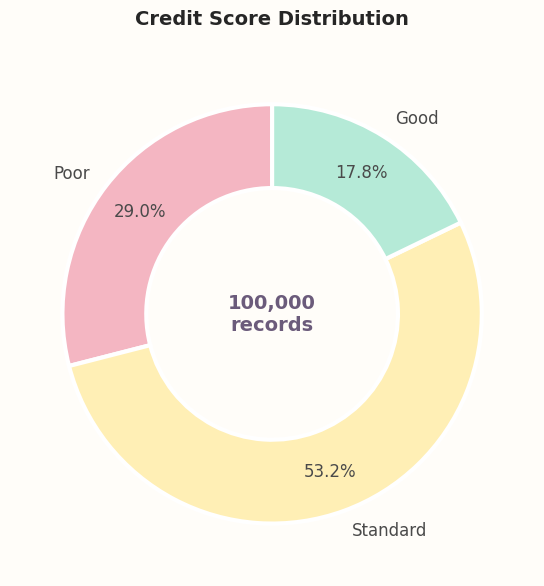

In [76]:
# ===== 11. CHART 1: CREDIT SCORE DISTRIBUTION (DONUT) =====

def donut_chart(data, col, colors):
    """Draws a pastel donut chart showing how many customers fall in each class."""
    counts = data[col].value_counts().reindex(["Poor", "Standard", "Good"])
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.pie(counts, labels=counts.index, colors=[colors[k] for k in counts.index],
           autopct="%1.1f%%", startangle=90, pctdistance=0.8,
           wedgeprops=dict(width=0.4, edgecolor="white", linewidth=3),
           textprops={"fontsize": 12, "color": "#4A4A4A"})
    ax.text(0, 0, f"{len(data):,}\nrecords", ha="center", va="center",
            fontsize=14, fontweight="bold", color="#6B5B7B")
    ax.set_title("Credit Score Distribution", pad=20)
    plt.tight_layout()
    plt.show()

donut_chart(df_clean, "Credit_Score", SCORE_COLORS)

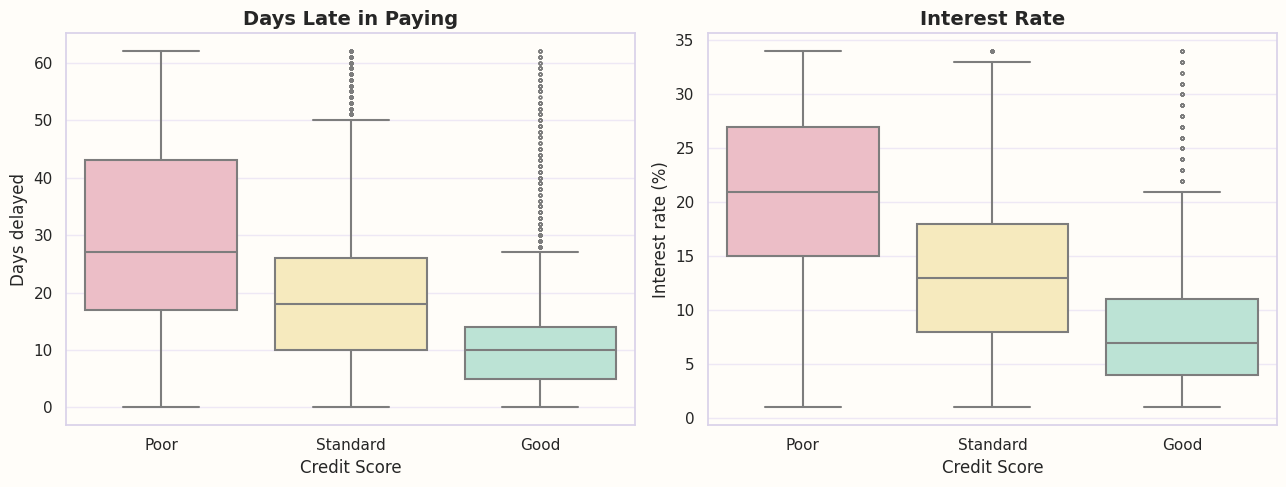

In [77]:
# ===== 12. CHART 2: PAYMENT DELAY AND INTEREST RATE BY CREDIT SCORE (BOX PLOT) =====

def score_boxplot(data, col, ax, title, ylabel):
    """Box plot of one column for each credit score class."""
    sns.boxplot(data=data, x="Credit_Score", y=col, hue="Credit_Score",
                order=["Poor", "Standard", "Good"], hue_order=["Poor", "Standard", "Good"],
                palette=SCORE_COLORS, legend=False, linewidth=1.5, fliersize=2, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Credit Score")
    ax.set_ylabel(ylabel)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
score_boxplot(df_clean, "Delay_from_due_date", axes[0], "Days Late in Paying", "Days delayed")
score_boxplot(df_clean, "Interest_Rate", axes[1], "Interest Rate", "Interest rate (%)")
plt.tight_layout()
plt.show()

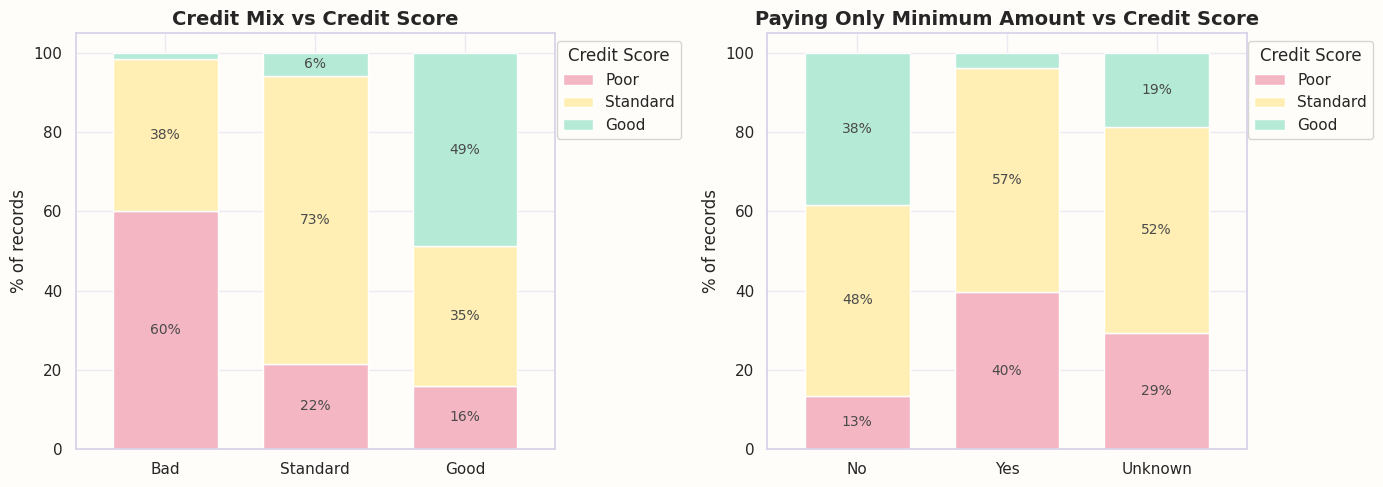

In [78]:
# ===== 13. CHART 3: CREDIT MIX AND MINIMUM PAYMENT VS CREDIT SCORE (STACKED BAR) =====

def stacked_pct_bar(data, col, order, ax, title):
    """Stacked bar where each bar adds up to 100% so groups can be compared fairly."""
    table = pd.crosstab(data[col], data["Credit_Score"], normalize="index") * 100
    table = table.reindex(order)[["Poor", "Standard", "Good"]]
    table.plot(kind="bar", stacked=True, ax=ax, width=0.7, edgecolor="white",
               color=[SCORE_COLORS[c] for c in table.columns])
    for container in ax.containers:     # write % inside bars (skip tiny ones)
        labels = [f"{b.get_height():.0f}%" if b.get_height() >= 5 else "" for b in container]
        ax.bar_label(container, labels=labels, label_type="center", fontsize=10, color="#4A4A4A")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("% of records")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Credit Score", loc="upper right", bbox_to_anchor=(1.28, 1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
stacked_pct_bar(df_clean, "Credit_Mix", ["Bad", "Standard", "Good"], axes[0], "Credit Mix vs Credit Score")
stacked_pct_bar(df_clean, "Payment_of_Min_Amount", ["No", "Yes", "Unknown"], axes[1], "Paying Only Minimum Amount vs Credit Score")
plt.tight_layout()
plt.show()

### Chart 1: Donut chart (Credit Score Distribution)
**Why this chart?** A donut shows how a whole splits into parts, which is perfect for 3 classes.
**Insight:** 53% of records are Standard, 29% Poor and only 18% Good. The classes are not equal in size (imbalanced).
**Business impact:** Almost 3 in 10 records are Poor, so a good risk filter is valuable. Also, any model must be checked per class, not only on overall accuracy.

### Chart 2: Box plots (Payment delay and Interest rate)
**Why this chart?** Box plots compare the middle value and the spread of a number across groups.
**Insight:** Poor customers pay about 27 days late (median) vs 10 days for Good. They also get a much higher interest rate (about 21% vs 7%).
**Business impact:** Late payment is an early warning sign that Paisabazaar can track. The risk is that high interest on Poor customers makes repayment harder, which can push them further down.

### Chart 3: 100% stacked bars (Credit Mix, Minimum payment)
**Why this chart?** Every bar adds up to 100%, so groups of different sizes can be compared fairly.
**Insight:** A "Bad" credit mix is 60% Poor. Customers who pay only the minimum amount are 40% Poor and only 4% Good.
**Business impact:** These are simple, visible signals for loan approval. The caution is that "Unknown" minimum-payment data (12%) hides some risk.

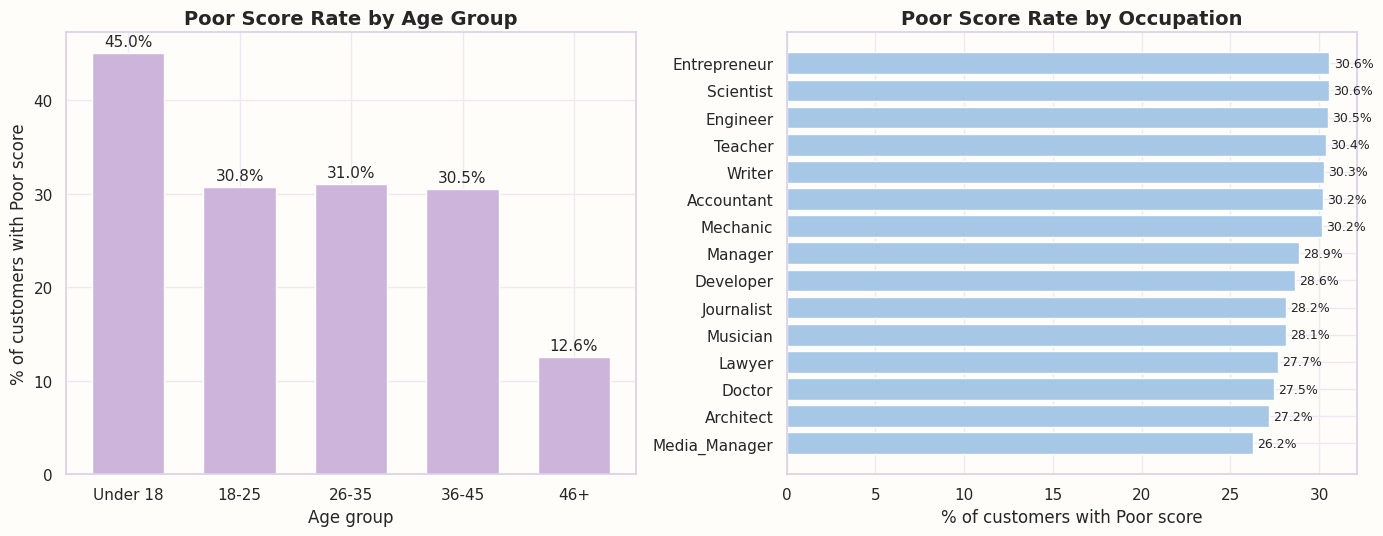

In [79]:
# ===== 14. CHART 4: % OF POOR CUSTOMERS BY AGE GROUP AND OCCUPATION (BAR CHART) =====

def poor_rate(data, col):
    """% of customers with a Poor score inside each group of the given column."""
    return ((data["Credit_Score"] == "Poor").groupby(data[col], observed=True).mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: by age group
age_rate = poor_rate(df_clean, "Age_Group")
axes[0].bar(age_rate.index.astype(str), age_rate.values, color=PASTEL["lavender"], edgecolor="white", width=0.65)
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=3)
axes[0].set_title("Poor Score Rate by Age Group")
axes[0].set_ylabel("% of customers with Poor score")
axes[0].set_xlabel("Age group")

# Right: by occupation (sorted)
occ_rate = poor_rate(df_clean, "Occupation").sort_values()
axes[1].barh(occ_rate.index, occ_rate.values, color=PASTEL["blue"], edgecolor="white")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%", padding=3, fontsize=9)
axes[1].set_title("Poor Score Rate by Occupation")
axes[1].set_xlabel("% of customers with Poor score")

plt.tight_layout()
plt.show()

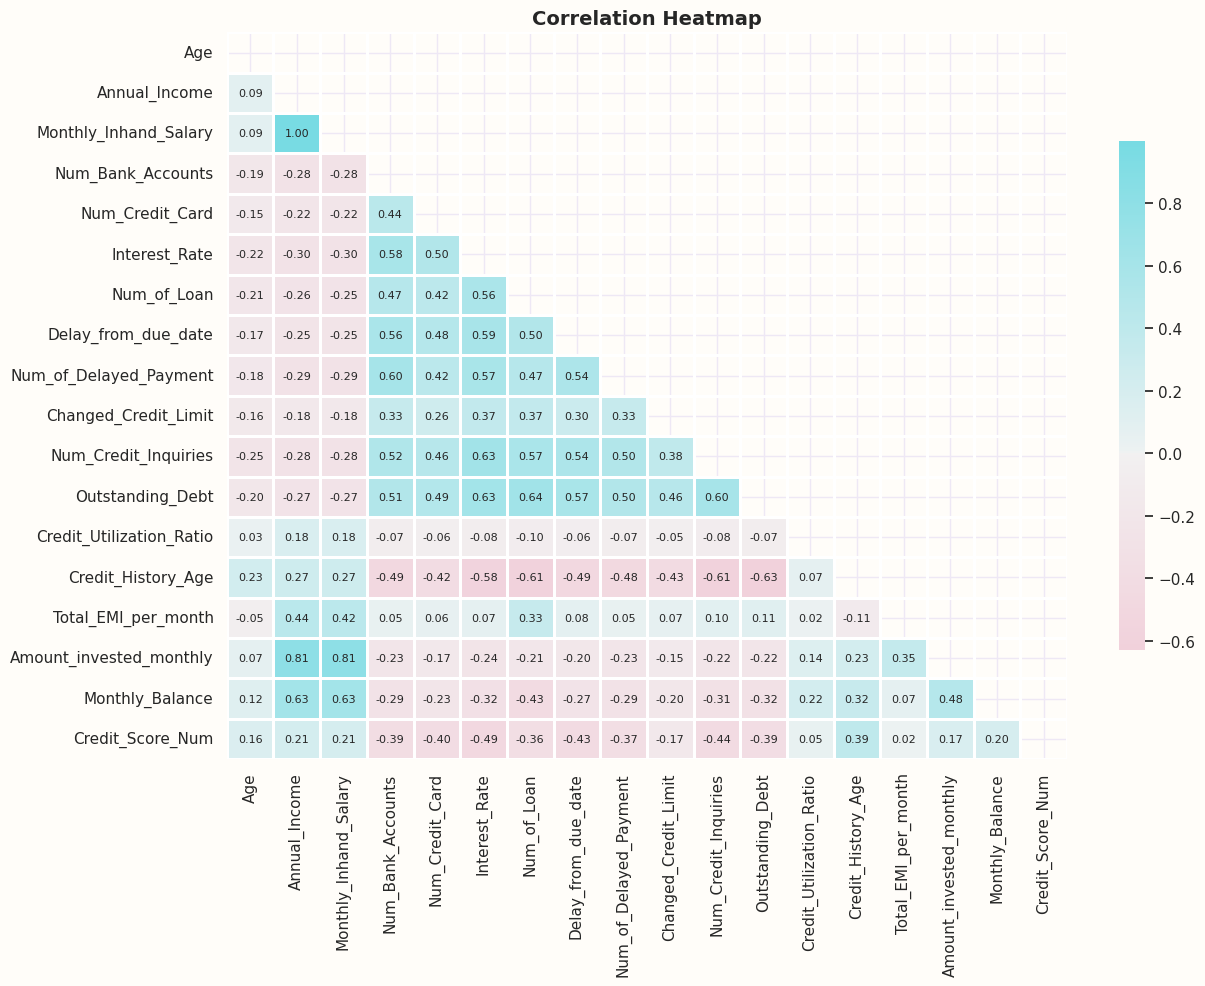

In [80]:
# ===== 15. CHART 5: CORRELATION HEATMAP =====

def correlation_heatmap(data, score_series):
    """Heatmap showing how strongly each pair of numeric columns moves together."""
    num = data.select_dtypes("number").drop(columns=["ID", "Customer_ID", "Month", "SSN"])
    num = num.assign(Credit_Score_Num=score_series)      # add the score (Poor=0, Standard=1, Good=2)
    corr = num.corr()
    mask = np.triu(np.ones_like(corr, dtype=bool))       # hide the repeated upper half
    cmap = sns.diverging_palette(350, 200, s=70, l=82, as_cmap=True)   # pink <-> blue
    plt.figure(figsize=(13, 10))
    sns.heatmap(corr, mask=mask, cmap=cmap, center=0, annot=True, fmt=".2f",
                annot_kws={"size": 8}, linewidths=1, linecolor="white",
                cbar_kws={"shrink": 0.7})
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()

correlation_heatmap(df, score_num)

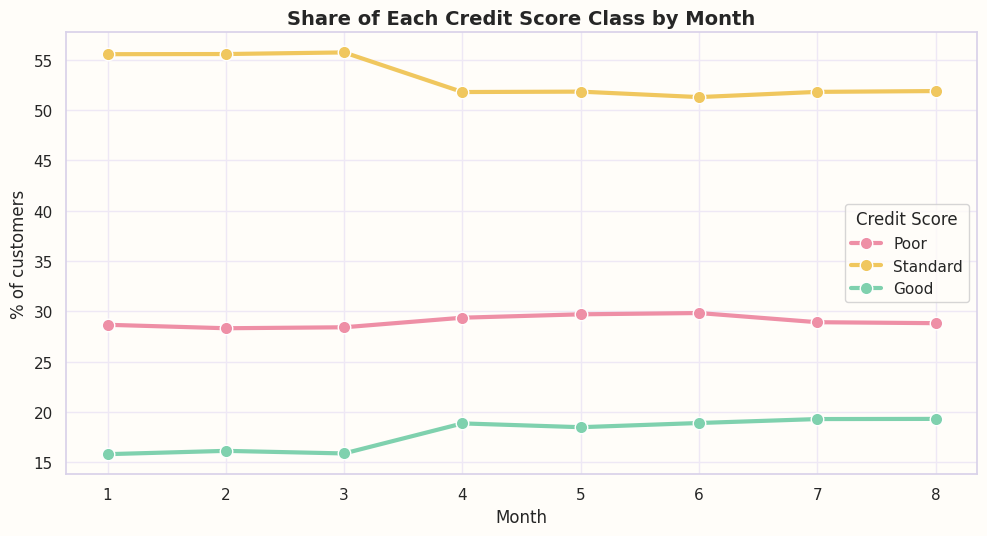

In [81]:
# ===== 16. CHART 6: CREDIT SCORE TREND OVER 8 MONTHS (LINE CHART) =====

LINE_COLORS = {"Poor": "#EE8FA6", "Standard": "#F0C75E", "Good": "#7FD1AE"}   # slightly deeper pastels so lines are visible

def monthly_trend(data):
    """% of records in each score class for every month."""
    return pd.crosstab(data["Month"], data["Credit_Score"], normalize="index") * 100

trend = monthly_trend(df_clean)

plt.figure(figsize=(10, 5.5))
for score in ["Poor", "Standard", "Good"]:
    plt.plot(trend.index, trend[score], marker="o", markersize=9, linewidth=3,
             color=LINE_COLORS[score], markeredgecolor="white", label=score)
plt.title("Share of Each Credit Score Class by Month")
plt.xlabel("Month")
plt.ylabel("% of customers")
plt.xticks(range(1, 9))
plt.legend(title="Credit Score")
plt.tight_layout()
plt.show()

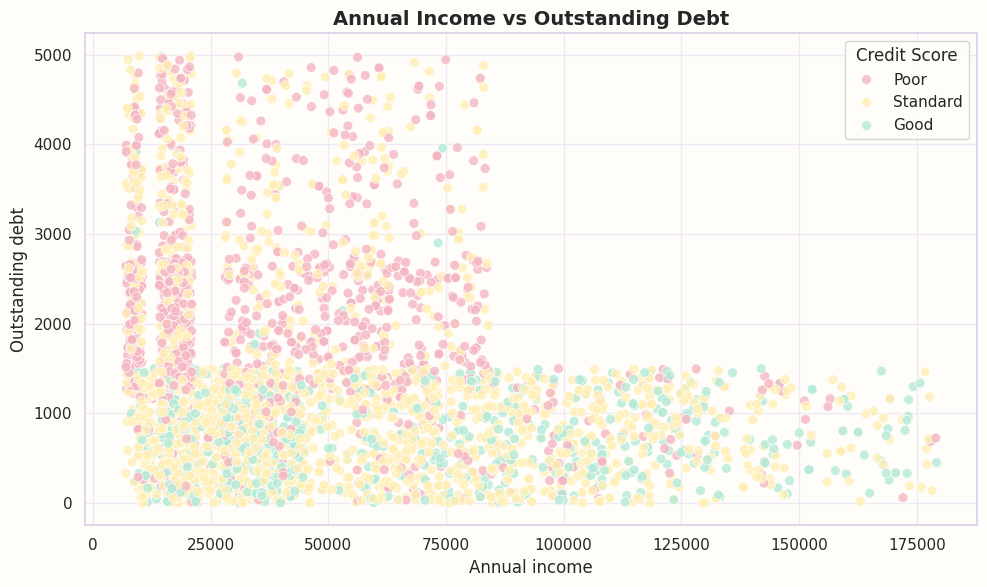

In [82]:
# ===== 17. CHART 7: INCOME VS OUTSTANDING DEBT (SCATTER PLOT) =====

# We plot a random sample of 4000 points so the chart stays clear and fast
sample = df_clean.sample(4000, random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x="Annual_Income", y="Outstanding_Debt", hue="Credit_Score",
                hue_order=["Poor", "Standard", "Good"], palette=SCORE_COLORS,
                s=50, alpha=0.8, edgecolor="white")
plt.title("Annual Income vs Outstanding Debt")
plt.xlabel("Annual income")
plt.ylabel("Outstanding debt")
plt.legend(title="Credit Score")
plt.tight_layout()
plt.show()

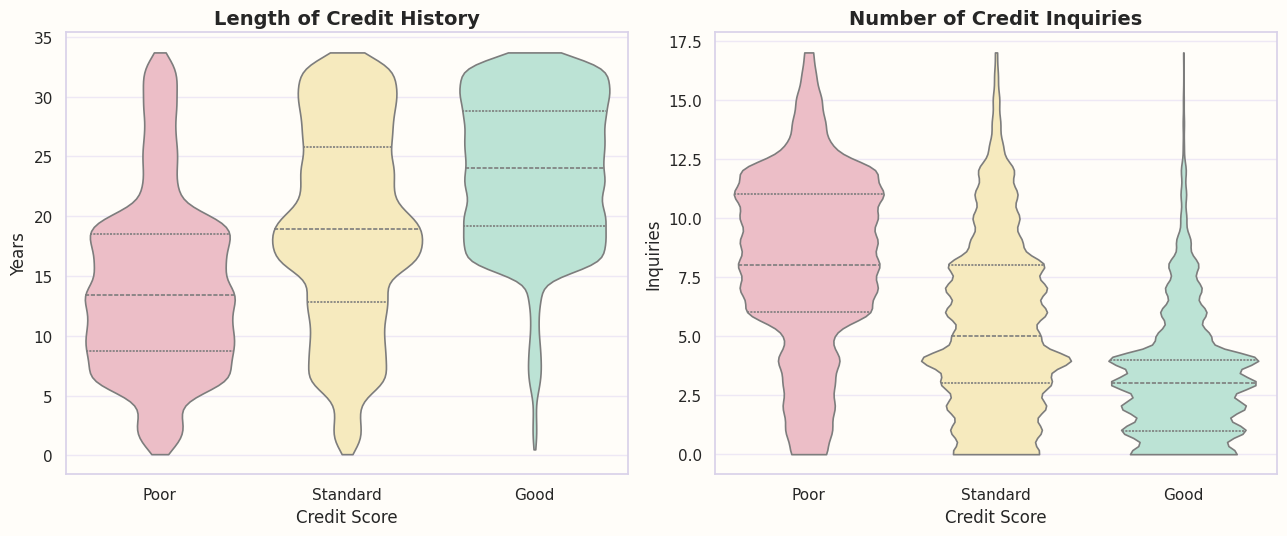

In [83]:
# ===== 18. CHART 8: CREDIT HISTORY LENGTH AND CREDIT INQUIRIES (VIOLIN PLOT) =====

def score_violin(data, col, ax, title, ylabel):
    """Violin plot: shows the full shape (spread) of a number for each credit score class."""
    sns.violinplot(data=data, x="Credit_Score", y=col, hue="Credit_Score",
                   order=["Poor", "Standard", "Good"], hue_order=["Poor", "Standard", "Good"],
                   palette=SCORE_COLORS, inner="quartile", cut=0, linewidth=1.2,
                   legend=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Credit Score")
    ax.set_ylabel(ylabel)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
score_violin(df_clean, "Credit_History_Years", axes[0], "Length of Credit History", "Years")
score_violin(df_clean, "Num_Credit_Inquiries", axes[1], "Number of Credit Inquiries", "Inquiries")
plt.tight_layout()
plt.show()

### Chart 4: Bar charts (Age group and Occupation)
**Why this chart?** Bars make it easy to compare one number (% Poor) across groups.
**Insight:** Under-18 customers are 45% Poor, ages 18 to 45 are about 31%, and 46+ only 12.6%. Occupation barely matters (26% to 31%).
**Business impact:** Age and experience matter more than job type. Under-18 records need a careful review since credit products are normally for adults.

### Chart 5: Correlation heatmap
**Why this chart?** It shows all relationships between numbers in one picture.
**Insight:** Annual_Income and Monthly_Inhand_Salary are the same information (1.00). Salary and money invested are strongly linked (0.81). Number of loans and debt are linked (0.64).
**Business impact:** Duplicate columns can be removed to make the model simpler without losing information.

### Chart 6: Line chart (trend over months)
**Why this chart?** Lines are the best way to show change over time.
**Insight:** The Good share rises from about 16% to 19% after month 3, Standard falls, and Poor stays flat (28% to 30%).
**Business impact:** Customers are slowly improving, but the Poor group is not shrinking, so it needs targeted help such as financial advice.

### Chart 7: Scatter plot (Income vs Debt)
**Why this chart?** It shows how two numbers move together and where each class sits.
**Insight:** Poor customers carry much more debt (median about 1,945 vs 736 for Good) at all income levels. Income alone does not decide the score.
**Business impact:** Debt level is a better risk signal than income, so approval rules should check debt and not only salary.

### Chart 8: Violin plots (Credit history, Inquiries)
**Why this chart?** It shows the whole spread of the data, not just the middle.
**Insight:** Longer history means a better score. Many credit inquiries means a worse score.
**Business impact:** Customers who apply for credit many times in a short period are higher risk. New customers with a short history need extra care.

## Hypothesis Testing
We test three statements that came from our charts. Significance level: alpha = 0.05.
We use tests that do not need a normal distribution, because our data is not bell-shaped.

### Hypothesis 1: Payment delay differs across credit score classes
- **H0 (null):** Days late are the same for Poor, Standard and Good customers.
- **H1 (alternate):** At least one class has different days late.
- **Test:** Kruskal-Wallis. **Why:** it compares 3 groups and does not need normal data.

### Hypothesis 2: Credit Mix and Credit Score are related
- **H0:** Credit Mix and Credit Score are independent (no link).
- **H1:** They are related.
- **Test:** Chi-square test of independence. **Why:** both columns are categories.

### Hypothesis 3: Poor customers pay a higher interest rate than Good customers
- **H0:** Interest rates are the same for Poor and Good customers.
- **H1:** Poor customers have a higher interest rate.
- **Test:** Mann-Whitney U (one-sided). **Why:** it compares 2 groups and does not need normal data.

In [84]:
# ===== 19. HYPOTHESIS TESTS =====

from scipy import stats
ALPHA = 0.05   # significance level

def fmt_p(p):
    """Shows very tiny p-values as '< 0.0001'."""
    return "< 0.0001" if p < 0.0001 else f"{p:.4f}"

def verdict(p):
    """Decision based on the p-value."""
    return "REJECT the null hypothesis (significant)" if p < ALPHA else "FAIL TO REJECT the null hypothesis (not significant)"

def score_group(col, label):
    """Values of one column for one credit score class."""
    return df_clean.loc[df_clean["Credit_Score"] == label, col]

# ---- Test 1: Kruskal-Wallis (delay vs score) ----
groups = [score_group("Delay_from_due_date", s) for s in ["Poor", "Standard", "Good"]]
H, p1 = stats.kruskal(*groups)
effect1 = H / (len(df_clean) - 1)       # epsilon-squared: size of the effect
print("🔹 TEST 1: Kruskal-Wallis (days late vs credit score)")
print(f"   H = {H:,.1f} | p-value = {fmt_p(p1)} | effect size = {effect1:.2f}")
print(f"   Decision: {verdict(p1)}\n")

# ---- Test 2: Chi-square (credit mix vs score) ----
table = pd.crosstab(df_clean["Credit_Mix"], df_clean["Credit_Score"])
chi2, p2, dof, _ = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))   # strength of link (0 to 1)
print("🔹 TEST 2: Chi-square (Credit Mix vs Credit Score)")
print(f"   Chi2 = {chi2:,.1f} | degrees of freedom = {dof} | p-value = {fmt_p(p2)} | Cramer's V = {cramers_v:.2f}")
print(f"   Decision: {verdict(p2)}\n")

# ---- Test 3: Mann-Whitney U (interest rate Poor vs Good) ----
poor_rate_vals = score_group("Interest_Rate", "Poor")
good_rate_vals = score_group("Interest_Rate", "Good")
U, p3 = stats.mannwhitneyu(poor_rate_vals, good_rate_vals, alternative="greater")
prob = U / (len(poor_rate_vals) * len(good_rate_vals))   # chance a random Poor customer has a higher rate than a random Good one
print("🔹 TEST 3: Mann-Whitney U (interest rate: Poor > Good)")
print(f"   U = {U:,.1f} | p-value = {fmt_p(p3)} | probability Poor > Good = {prob:.2f}")
print(f"   Decision: {verdict(p3)}")

🔹 TEST 1: Kruskal-Wallis (days late vs credit score)
   H = 19,448.8 | p-value = < 0.0001 | effect size = 0.19
   Decision: REJECT the null hypothesis (significant)

🔹 TEST 2: Chi-square (Credit Mix vs Credit Score)
   Chi2 = 40,489.4 | degrees of freedom = 4 | p-value = < 0.0001 | Cramer's V = 0.45
   Decision: REJECT the null hypothesis (significant)

🔹 TEST 3: Mann-Whitney U (interest rate: Poor > Good)
   U = 449,707,341.5 | p-value = < 0.0001 | probability Poor > Good = 0.87
   Decision: REJECT the null hypothesis (significant)


### Hypothesis Results
| # | Statement | Test | p-value | Strength | Decision |
|---|-----------|------|---------|----------|----------|
| 1 | Delay differs across score classes | Kruskal-Wallis | < 0.0001 | Large (0.19) | Reject H0 |
| 2 | Credit Mix is linked to Credit Score | Chi-square | < 0.0001 | Strong (V = 0.45) | Reject H0 |
| 3 | Poor customers pay higher interest | Mann-Whitney U | < 0.0001 | 87% chance | Reject H0 |

**Conclusion:** All three statements are supported by the data.
**Note:** With 100,000 rows, p-values become tiny very easily. So we also report the strength of each result.
Also, each customer appears 8 times, so rows are not fully independent. The p-values are a little optimistic, but the strength numbers show the effects are real.

## Feature Engineering and Pre-processing
Before building a model, we prepare the data. Our decisions:

| Step | Decision | Why |
|------|----------|-----|
| Outliers | Check with the IQR rule, then **keep** them | Values are real (high debt, large EMI), not errors. Tree models are not affected much. |
| Type_of_Loan | Convert 6,261 text combinations into 9 simple 0/1 loan flags | Raw text has too many unique values for a model |
| Drop Customer_ID, Month | Not used as features | Customer_ID is only a label. Month could leak information. |
| Drop Monthly_Inhand_Salary, Credit_History_Years | Duplicates of Annual_Income and Credit_History_Age | Same information twice adds no value |
| Drop Occupation, Age_Group, Income_Group | Occupation is weak (26% to 31% Poor everywhere). The two groups are copies of Age and Income. | Keeps the model simple |
| Encoding | Credit_Mix becomes 0/1/2 (Bad < Standard < Good). Payment columns are one-hot encoded. | Models need numbers |
| Scaling | Only for Logistic Regression, inside a Pipeline | Tree models do not need it |
| Dimensionality reduction | Not needed | We only have about 37 features |
| Data split | 80/20 split **by customer** | The same customer's 8 months never appear in both train and test, so no leakage |
| Imbalance | Use class_weight="balanced" | Simple and free. We also report macro-F1 and per-class recall. |

🔹 OUTLIERS PER COLUMN


Column,Outliers,Outlier %
Monthly_Balance,"7,400",7.4%
Outstanding_Debt,"5,272",5.3%
Total_EMI_per_month,"5,044",5.0%
Amount_invested_monthly,"4,464",4.5%
Delay_from_due_date,"4,002",4.0%
Annual_Income,"2,000",2.0%
Num_Credit_Inquiries,787,0.8%
Interest_Rate,0,0.0%
Num_Credit_Card,0,0.0%
Num_of_Delayed_Payment,0,0.0%


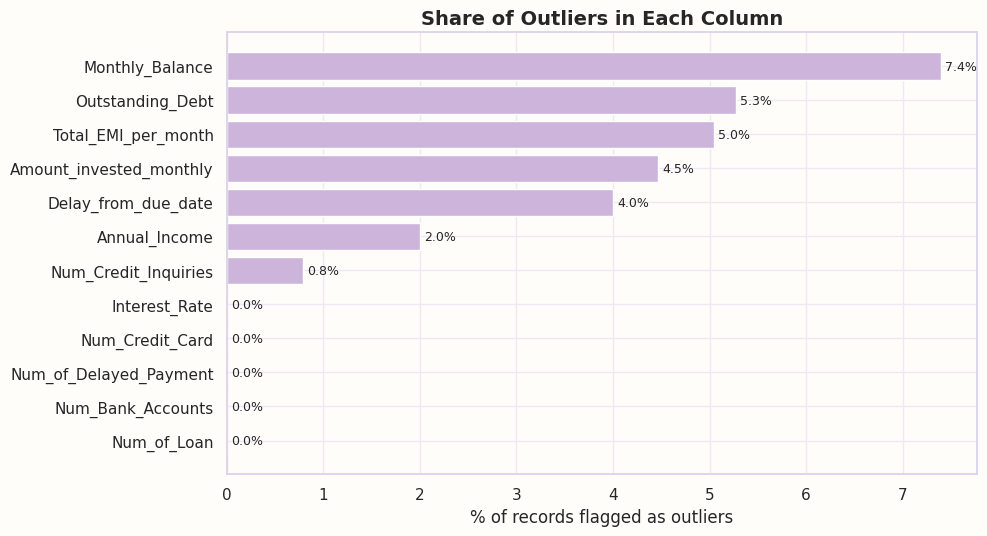


✅ Decision: we KEEP the outliers. They are real values (not typing errors),
   and tree-based models are not sensitive to them.


In [85]:
# ===== 20. OUTLIER CHECK (IQR RULE) =====

# IQR rule: a value is an outlier if it is far outside the middle 50% of the data
def outlier_report(data, cols):
    """Counts outliers in each column using the IQR rule."""
    rows = []
    for c in cols:
        q1, q3 = data[c].quantile(0.25), data[c].quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = ((data[c] < low) | (data[c] > high)).sum()
        rows.append({"Column": c, "Outliers": n_out, "Outlier %": n_out / len(data) * 100})
    return pd.DataFrame(rows).sort_values("Outlier %", ascending=False).reset_index(drop=True)

outlier_cols = ["Annual_Income", "Outstanding_Debt", "Interest_Rate", "Num_Credit_Card",
                "Num_Bank_Accounts", "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment",
                "Num_Credit_Inquiries", "Total_EMI_per_month", "Amount_invested_monthly", "Monthly_Balance"]

out_table = outlier_report(df_clean, outlier_cols)
print("🔹 OUTLIERS PER COLUMN")
display(out_table.style.format({"Outliers": "{:,.0f}", "Outlier %": "{:.1f}%"}).hide(axis="index"))

# Pastel bar chart of outlier percentages
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(out_table["Column"][::-1], out_table["Outlier %"][::-1],
        color=PASTEL["lavender"], edgecolor="white")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=9)
ax.set_title("Share of Outliers in Each Column")
ax.set_xlabel("% of records flagged as outliers")
plt.tight_layout()
plt.show()

print("\n✅ Decision: we KEEP the outliers. They are real values (not typing errors),")
print("   and tree-based models are not sensitive to them.")

In [86]:
# ===== 21. TYPE_OF_LOAN -> 0/1 FLAGS =====

# Type_of_Loan has 6,261 different text combinations (too many for a model).
# We turn it into 9 simple columns: 1 = customer has this loan type, 0 = does not.
LOAN_TYPES = ["Auto Loan", "Credit-Builder Loan", "Debt Consolidation Loan", "Home Equity Loan",
              "Mortgage Loan", "Payday Loan", "Personal Loan", "Student Loan", "Not Specified"]

def add_loan_flags(data):
    """Adds one 0/1 column for each loan type found inside the Type_of_Loan text."""
    d = data.copy()
    for loan in LOAN_TYPES:
        name = "Loan_" + loan.replace(" Loan", "").replace("-", "_").replace(" ", "_")
        d[name] = d["Type_of_Loan"].str.contains(loan, regex=False).astype(int)
    return d

df_loans = add_loan_flags(df_clean)
loan_cols = [c for c in df_loans.columns if c.startswith("Loan_")]

print(f"✅ Created {len(loan_cols)} loan flag columns")
print("\n🔹 HOW MANY RECORDS HAVE EACH LOAN TYPE")
print(df_loans[loan_cols].sum().to_string())

print("\n🔹 EXAMPLE ROWS (original text next to the new flags)")
display(df_loans[["Type_of_Loan"] + loan_cols].drop_duplicates("Type_of_Loan").head(4))

✅ Created 9 loan flag columns

🔹 HOW MANY RECORDS HAVE EACH LOAN TYPE
Loan_Auto                  30560
Loan_Credit_Builder        31728
Loan_Debt_Consolidation    31040
Loan_Home_Equity           31400
Loan_Mortgage              31360
Loan_Payday                31944
Loan_Personal              31104
Loan_Student               31040
Loan_Not_Specified         31680

🔹 EXAMPLE ROWS (original text next to the new flags)


,Type_of_Loan,Loan_Auto,Loan_Credit_Builder,Loan_Debt_Consolidation,Loan_Home_Equity,Loan_Mortgage,Loan_Payday,Loan_Personal,Loan_Student,Loan_Not_Specified
0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",1,1,0,1,0,0,1,0,0
8,Credit-Builder Loan,0,1,0,0,0,0,0,0,0
16,"Auto Loan, Auto Loan, and Not Specified",1,0,0,0,0,0,0,0,1
24,Not Specified,0,0,0,0,0,0,0,0,1


In [87]:
# ===== 22. BUILD FEATURES (X) AND TARGET (y) =====

def fix_score_labels(data):
    """Removes spaces and fixes capital letters in Credit_Score (e.g. ' good' -> 'Good')."""
    d = data.copy()
    d["Credit_Score"] = d["Credit_Score"].astype(str).str.strip().str.title()
    return d

def build_features(data):
    """Drops unneeded columns, encodes text columns, and returns X (features), y (target), groups (customer ids)."""
    d = data.copy()

    # Keep customer ids aside: we need them later to split by customer
    groups = d["Customer_ID"].copy()

    # Target: Poor=0, Standard=1, Good=2
    y = d["Credit_Score"].astype(str).map({"Poor": 0, "Standard": 1, "Good": 2})
    if y.isnull().any():
        print("❌ Unexpected values found in Credit_Score:", d["Credit_Score"].unique())
        raise ValueError("Credit_Score has values other than Poor / Standard / Good")
    y = y.astype(int)

    # Ordinal encoding: Credit_Mix has a natural order (Bad < Standard < Good)
    d["Credit_Mix"] = d["Credit_Mix"].map({"Bad": 0, "Standard": 1, "Good": 2})

    # Drop columns we do not want the model to use (reasons are in Cell 26)
    drop_cols = ["Customer_ID", "Month", "Monthly_Inhand_Salary", "Credit_History_Years",
                 "Type_of_Loan", "Occupation", "Age_Group", "Income_Group", "Credit_Score"]
    d = d.drop(columns=drop_cols)

    # One-hot encoding: each category becomes its own 0/1 column
    d = pd.get_dummies(d, columns=["Payment_of_Min_Amount", "Payment_Behaviour"], dtype=int)
    return d, y, groups

# Rebuild the tables from the raw data so nothing old is left over
df = fix_score_labels(df)
df_clean = clean_data(df)
df_loans = add_loan_flags(df_clean)

X, y, groups = build_features(df_loans)

print(f"✅ Feature table ready: {X.shape[0]:,} rows x {X.shape[1]} features")
print(f"🔹 Missing values in X: {X.isnull().sum().sum()}")
print("\n🔹 TARGET CLASSES (0 = Poor, 1 = Standard, 2 = Good)")
print(y.value_counts().sort_index().to_string())

✅ Feature table ready: 100,000 rows x 37 features
🔹 Missing values in X: 0

🔹 TARGET CLASSES (0 = Poor, 1 = Standard, 2 = Good)
Credit_Score
0    28998
1    53174
2    17828


In [88]:
# ===== 23. TRAIN / TEST SPLIT (BY CUSTOMER) =====

from sklearn.model_selection import GroupShuffleSplit

def group_split(X, y, groups, test_size=0.2, seed=42):
    """Splits data 80/20 so that all 8 rows of a customer go to the SAME side (no leakage)."""
    splitter = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    train_idx, test_idx = next(splitter.split(X, y, groups))
    return (X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx],
            groups.iloc[train_idx], groups.iloc[test_idx])

X_train, X_test, y_train, y_test, g_train, g_test = group_split(X, y, groups)

print(f"🔹 Training set: {X_train.shape[0]:,} rows ({g_train.nunique():,} customers)")
print(f"🔹 Test set:     {X_test.shape[0]:,} rows ({g_test.nunique():,} customers)")

# Safety check: no customer should be in both sets
overlap = len(set(g_train) & set(g_test))
print(f"\n🔒 Customers present in BOTH sets: {overlap}  (must be 0)")

# Class balance check
print("\n🔹 CLASS SPLIT (%)   Poor / Standard / Good")
print("Train:", (y_train.value_counts(normalize=True).sort_index() * 100).round(1).tolist())
print("Test: ", (y_test.value_counts(normalize=True).sort_index() * 100).round(1).tolist())

🔹 Training set: 80,000 rows (10,000 customers)
🔹 Test set:     20,000 rows (2,500 customers)

🔒 Customers present in BOTH sets: 0  (must be 0)

🔹 CLASS SPLIT (%)   Poor / Standard / Good
Train: [29.0, 53.2, 17.8]
Test:  [29.1, 53.1, 17.8]


## Machine Learning Models
**Goal:** predict whether a customer's credit score is Poor, Standard or Good.

### Three models (simple to advanced)
1. **Logistic Regression**: a simple baseline. It draws straight-line boundaries between classes.
2. **Random Forest**: many decision trees that vote together.
3. **Gradient Boosting**: trees built one after another, each fixing the mistakes of the previous one.

### How we test them fairly
- **Cross-validation by customer (GroupKFold, 3 folds):** training data is split in 3 parts. The model trains on 2 parts and is checked on the 3rd, three times. A customer's 8 rows always stay together.
- **class_weight = "balanced":** gives more importance to the smaller classes (Poor and Good).

### Metrics (in business words)
| Metric | Meaning |
|--------|---------|
| Accuracy | Out of 100 customers, how many did we classify correctly? |
| Macro F1 | A fair average score across all 3 classes, so the big Standard class cannot hide weak results |
| Poor Recall | Out of 100 truly risky (Poor) customers, how many did we catch? This is the most important metric for risk control. |

In [89]:
# ===== 24. MODELS AND HELPER FUNCTIONS =====
import time
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, recall_score

# 3 folds, split by customer so the same customer is never in two folds
CV = GroupKFold(n_splits=3)

def get_models():
    """Returns our 3 models. Logistic Regression gets a scaler inside a Pipeline (it needs scaled numbers)."""
    return {
        "Logistic Regression": Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))]),
        "Random Forest": RandomForestClassifier(
            n_estimators=100, max_depth=12, min_samples_leaf=5,
            class_weight="balanced", n_jobs=-1, random_state=42),
        "Gradient Boosting": HistGradientBoostingClassifier(
            class_weight="balanced", random_state=42),
    }

def score_predictions(y_true, y_pred):
    """Calculates our 3 main metrics from true and predicted labels."""
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Macro F1": f1_score(y_true, y_pred, average="macro"),
            "Poor Recall": recall_score(y_true == 0, y_pred == 0)}   # 0 = Poor class

def cv_scores(model, X, y, groups):
    """Cross-validated scores: every row is predicted by a model that never saw its customer."""
    pred = cross_val_predict(model, X, y, cv=CV, groups=groups)
    return score_predictions(y, pred)

print("✅ Helper functions ready. Models available:")
for name in get_models():
    print("   •", name)

✅ Helper functions ready. Models available:
   • Logistic Regression
   • Random Forest
   • Gradient Boosting


In [90]:
# ===== 25. CROSS-VALIDATION OF ALL 3 MODELS =====

def run_cv_all(models, X, y, groups):
    """Runs cross-validation for every model and returns a results table."""
    rows = {}
    for name, model in models.items():
        start = time.time()
        scores = cv_scores(model, X, y, groups)
        scores["Time (sec)"] = time.time() - start
        rows[name] = scores
        print(f"✅ {name} finished in {scores['Time (sec)']:.0f} sec")
    return pd.DataFrame(rows).T

print("⏳ Running cross-validation (this takes about 1 to 2 minutes)...\n")
cv_results = run_cv_all(get_models(), X_train, y_train, g_train)

print("\n📊 CROSS-VALIDATION RESULTS (training data only)")
display(cv_results.style.format({"Accuracy": "{:.1%}", "Macro F1": "{:.1%}",
                                 "Poor Recall": "{:.1%}", "Time (sec)": "{:.0f}"})
        .background_gradient(cmap="BuPu", subset=["Accuracy", "Macro F1", "Poor Recall"]))

⏳ Running cross-validation (this takes about 1 to 2 minutes)...

✅ Logistic Regression finished in 6 sec
✅ Random Forest finished in 30 sec
✅ Gradient Boosting finished in 19 sec

📊 CROSS-VALIDATION RESULTS (training data only)


,Accuracy,Macro F1,Poor Recall,Time (sec)
Logistic Regression,65.5%,64.9%,67.5%,6
Random Forest,68.4%,67.8%,77.9%,30
Gradient Boosting,68.9%,68.1%,73.5%,19


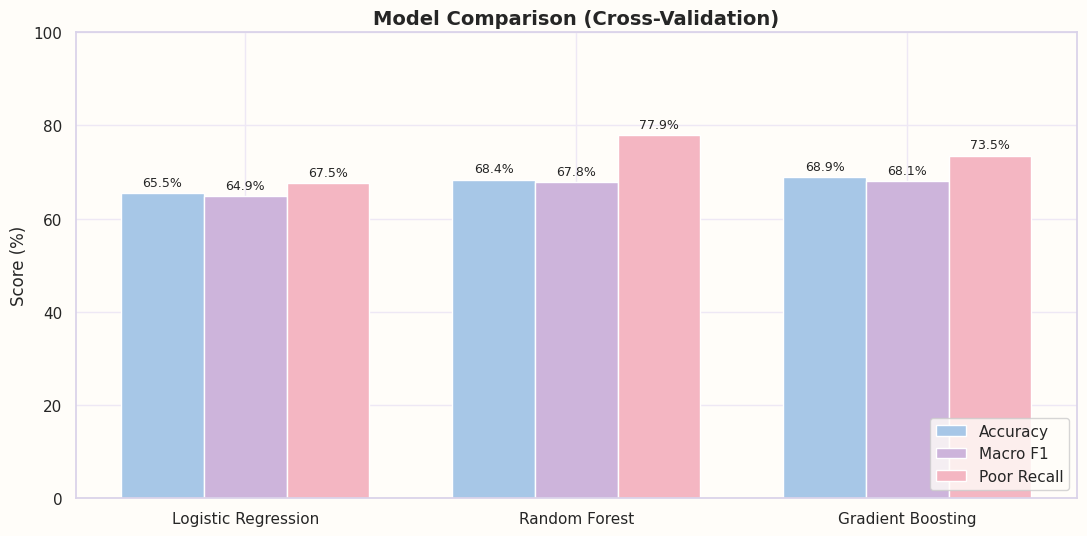

In [91]:
# ===== 26. CHART 9: MODEL COMPARISON (GROUPED BAR CHART) =====

def plot_model_comparison(results, title):
    """Pastel grouped bars: Accuracy, Macro F1 and Poor Recall for each model."""
    metrics = ["Accuracy", "Macro F1", "Poor Recall"]
    colors = [PASTEL["blue"], PASTEL["lavender"], PASTEL["pink"]]
    x = np.arange(len(results))
    width = 0.25
    fig, ax = plt.subplots(figsize=(11, 5.5))
    for i, (metric, color) in enumerate(zip(metrics, colors)):
        bars = ax.bar(x + (i - 1) * width, results[metric] * 100, width,
                      label=metric, color=color, edgecolor="white")
        ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(results.index)
    ax.set_ylim(0, 100)
    ax.set_ylabel("Score (%)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

plot_model_comparison(cv_results, "Model Comparison (Cross-Validation)")

### What the cross-validation shows
- **Logistic Regression** (baseline): about 65% accuracy. Fast and simple, but it misses more risky customers.
- **Random Forest:** about 68% accuracy and the best Poor recall (about 78%): it catches the most risky customers.
- **Gradient Boosting:** the best accuracy (69%) and macro F1 (68%), with Poor recall of about 74%.
- All three beat random guessing (33%), and the tree models clearly beat the baseline. This means the relationship between the features and credit score is not a straight line.
- **Next step:** we tune the two tree models to squeeze out more performance, then test on the unseen 20% of customers.

## Hyperparameter Tuning
Every model has "settings" (called hyperparameters), such as how deep the trees can grow.
Instead of guessing, we let the computer try several combinations and keep the best one.

- **Method:** Randomized Search. It tries a limited number of random combinations, so it is fast.
- **Fair testing:** every combination is checked with 3-fold cross-validation split by customer.
- **Score used to choose:** Macro F1, so the small classes (Poor and Good) count equally.
- **Models tuned:** Random Forest and Gradient Boosting (the two best models).
- **Data used:** training data only. The test data stays untouched until the final check.

In [92]:
# ===== 27. HYPERPARAMETER TUNING (RANDOMIZED SEARCH) =====

from sklearn.model_selection import RandomizedSearchCV

# The settings we let the search try for each model
def get_search_spaces():
    """Returns each model with the settings to try and how many random combinations to test."""
    return {
        "Random Forest": (
            RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=42),
            {"max_depth": [10, 14, 18], "min_samples_leaf": [2, 5, 10], "max_features": ["sqrt", 0.5]},
            3),
        "Gradient Boosting": (
            HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
            {"learning_rate": [0.03, 0.05, 0.1], "max_iter": [200, 300],
             "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [20, 50, 100]},
            5),
    }

def tune_all(X, y, groups):
    """Runs a randomized search for each model. Returns the best version of each model."""
    tuned = {}
    for name, (model, space, n_iter) in get_search_spaces().items():
        start = time.time()
        search = RandomizedSearchCV(model, space, n_iter=n_iter, scoring="f1_macro",
                                    cv=CV, random_state=42, refit=True)
        search.fit(X, y, groups=groups)       # groups keep each customer's rows together
        tuned[name] = search.best_estimator_
        print(f"✅ {name} finished in {time.time() - start:.0f} sec")
        print(f"   Best settings: {search.best_params_}")
        print(f"   Best cross-validation Macro F1: {search.best_score_:.1%}\n")
    return tuned

print("⏳ Tuning models (this can take about 4 to 7 minutes, please wait)...\n")
tuned_models = tune_all(X_train, y_train, g_train)
print("🎉 Tuning complete. Best models are saved in 'tuned_models'.")

⏳ Tuning models (this can take about 4 to 7 minutes, please wait)...

✅ Random Forest finished in 114 sec
   Best settings: {'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 14}
   Best cross-validation Macro F1: 67.9%

✅ Gradient Boosting finished in 255 sec
   Best settings: {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 300, 'learning_rate': 0.03}
   Best cross-validation Macro F1: 68.2%

🎉 Tuning complete. Best models are saved in 'tuned_models'.


🔹 FINAL TEST ON UNSEEN CUSTOMERS (20% of customers)



,Accuracy,Macro Precision,Macro Recall,Macro F1,Poor Recall
Logistic Regression,65.8%,64.1%,69.4%,65.0%,67.2%
Random Forest,67.7%,66.4%,72.2%,67.2%,78.1%
Gradient Boosting,68.7%,67.0%,72.4%,68.1%,76.3%



🏆 FINAL MODEL: Gradient Boosting
   Macro F1 = 68.1% | Poor Recall = 76.3% | Accuracy = 68.7%


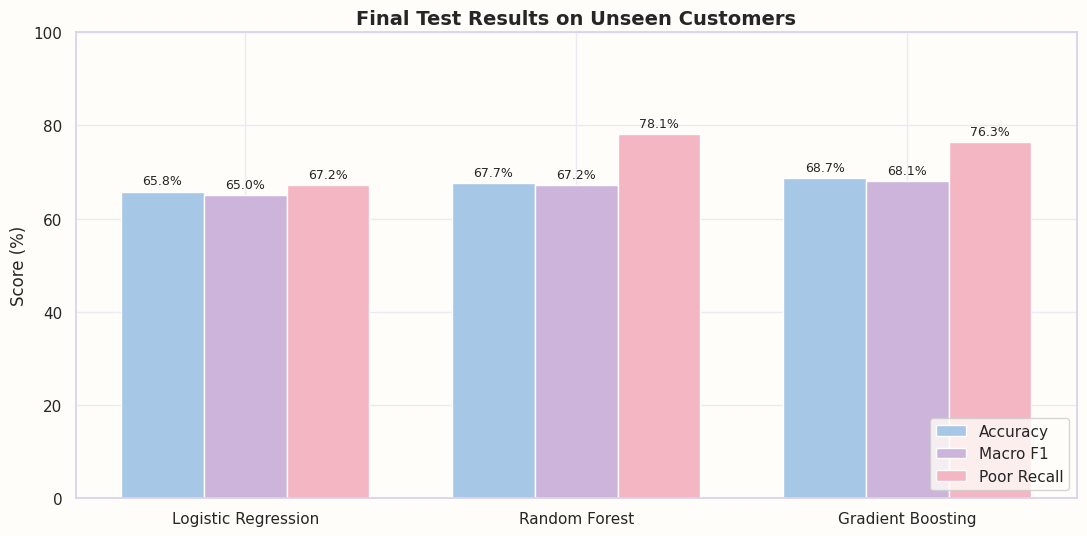

In [93]:
# ===== 28. FINAL TEST: TUNED MODELS VS BASELINE (UNSEEN 20% CUSTOMERS) =====

# Needs from earlier cells: X_train, X_test, y_train, y_test, tuned_models, get_models, PASTEL
from sklearn.metrics import precision_score

def full_scores(y_true, y_pred):
    """Calculates all 5 test metrics from true and predicted labels."""
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Macro Precision": precision_score(y_true, y_pred, average="macro"),
            "Macro Recall": recall_score(y_true, y_pred, average="macro"),
            "Macro F1": f1_score(y_true, y_pred, average="macro"),
            "Poor Recall": recall_score(y_true == 0, y_pred == 0)}

def test_all(final_models, X_tr, y_tr, X_te, y_te):
    """Fits the baseline on the train set, then scores every model on the unseen test set."""
    baseline = get_models()["Logistic Regression"].fit(X_tr, y_tr)   # tuned models are already fitted
    all_models = {"Logistic Regression": baseline, **final_models}
    preds = {name: m.predict(X_te) for name, m in all_models.items()}
    table = pd.DataFrame({name: full_scores(y_te, p) for name, p in preds.items()}).T
    return all_models, preds, table

print("🔹 FINAL TEST ON UNSEEN CUSTOMERS (20% of customers)\n")
all_models, test_preds, test_results = test_all(tuned_models, X_train, y_train, X_test, y_test)
display(test_results.style.format("{:.1%}")
        .background_gradient(cmap="BuPu", subset=["Accuracy", "Macro F1", "Poor Recall"]))

# Choose the final model: highest Macro F1 (ties go to the higher Poor Recall)
best_name = test_results.sort_values(["Macro F1", "Poor Recall"], ascending=False).index[0]
final_model, final_pred = all_models[best_name], test_preds[best_name]
print(f"\n🏆 FINAL MODEL: {best_name}")
print(f"   Macro F1 = {test_results.loc[best_name, 'Macro F1']:.1%} | "
      f"Poor Recall = {test_results.loc[best_name, 'Poor Recall']:.1%} | "
      f"Accuracy = {test_results.loc[best_name, 'Accuracy']:.1%}")

# Pastel chart of the test results
fig, ax = plt.subplots(figsize=(11, 5.5))
metrics = ["Accuracy", "Macro F1", "Poor Recall"]
colors = [PASTEL["blue"], PASTEL["lavender"], PASTEL["pink"]]
x = np.arange(len(test_results))
for i, (m, c) in enumerate(zip(metrics, colors)):
    bars = ax.bar(x + (i - 1) * 0.25, test_results[m] * 100, 0.25, label=m, color=c, edgecolor="white")
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(test_results.index)
ax.set_ylim(0, 100); ax.set_ylabel("Score (%)")
ax.set_title("Final Test Results on Unseen Customers")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

🔹 CONFUSION MATRIX: Gradient Boosting



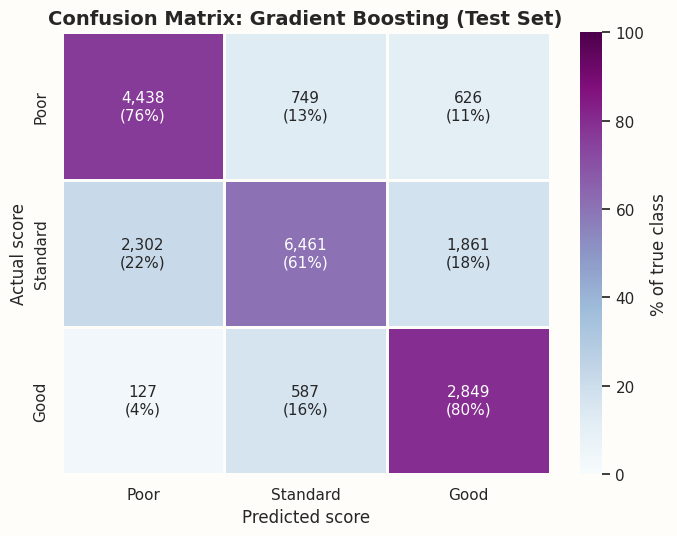


🔹 CLASSIFICATION REPORT (per class)


,precision,recall,f1-score,support
Poor,64.6%,76.3%,70.0%,"5,813"
Standard,82.9%,60.8%,70.1%,"10,624"
Good,53.4%,80.0%,64.0%,"3,563"
accuracy,68.7%,68.7%,68.7%,1
macro avg,67.0%,72.4%,68.1%,"20,000"
weighted avg,72.3%,68.7%,69.0%,"20,000"



🔹 IN PLAIN WORDS
• Poor recall 76%: out of 100 truly risky customers, we catch about 76.
• Good precision 53%: out of 100 customers we call 'Good', about 53 really are Good.
• Risky customers wrongly called Good: 10.8% (the most costly mistake).


In [94]:
# ===== 29. CONFUSION MATRIX AND CLASSIFICATION REPORT (FINAL MODEL) =====

# Needs from earlier cells: final_model, final_pred, best_name, y_test
from sklearn.metrics import confusion_matrix, classification_report

CLASS_NAMES = ["Poor", "Standard", "Good"]

def plot_confusion(y_true, y_pred, title):
    """Pastel heatmap: counts and % of each true class (each row adds up to 100%)."""
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    labels = np.array([[f"{n:,}\n({p:.0f}%)" for n, p in zip(r1, r2)] for r1, r2 in zip(cm, cm_pct)])
    fig, ax = plt.subplots(figsize=(7, 5.5))
    sns.heatmap(cm_pct, annot=labels, fmt="", cmap="BuPu", vmin=0, vmax=100, linewidths=2,
                linecolor="#FFFDF9", cbar_kws={"label": "% of true class"},
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Predicted score"); ax.set_ylabel("Actual score"); ax.set_title(title)
    plt.tight_layout()
    plt.show()
    return cm

print(f"🔹 CONFUSION MATRIX: {best_name}\n")
cm = plot_confusion(y_test, final_pred, f"Confusion Matrix: {best_name} (Test Set)")

# Per-class report as a table
report = pd.DataFrame(classification_report(y_test, final_pred, target_names=CLASS_NAMES,
                                            output_dict=True)).T
print("\n🔹 CLASSIFICATION REPORT (per class)")
display(report.style.format({"precision": "{:.1%}", "recall": "{:.1%}", "f1-score": "{:.1%}", "support": "{:,.0f}"})
        .background_gradient(cmap="BuPu", subset=["precision", "recall", "f1-score"]))

# Plain-language reading of the key numbers
poor_rec = cm[0, 0] / cm[0].sum(); good_prec = cm[2, 2] / cm[:, 2].sum()
poor_as_good = cm[0, 2] / cm[0].sum()
print("\n🔹 IN PLAIN WORDS")
print(f"• Poor recall {poor_rec:.0%}: out of 100 truly risky customers, we catch about {poor_rec*100:.0f}.")
print(f"• Good precision {good_prec:.0%}: out of 100 customers we call 'Good', about {good_prec*100:.0f} really are Good.")
print(f"• Risky customers wrongly called Good: {poor_as_good:.1%} (the most costly mistake).")

### Confusion Matrix and Classification Report: how to read them
**Why this chart?** A confusion matrix shows exactly where the model is right and where it mixes up classes. Accuracy alone hides this.

**How to read it:**
- Each **row** is the real score. Each **column** is what the model predicted. The diagonal (top-left to bottom-right) shows correct predictions.
- **Poor recall** = out of 100 truly risky customers, how many we catch. This is our most important number for risk control.
- **Good precision** = out of 100 customers we call "Good", how many really are Good. This shows how safe it is to approve them.
- **Macro F1** = a fair average over all 3 classes, so the big Standard class cannot hide weak results.

**Insight:** The final model is **Gradient Boosting**. It catches about **76%** of Poor customers and about **80%** of Good customers. Only about **53%** of the customers it calls Good really are Good, so a "Good" label should be double-checked. About **10.8%** of Poor customers are wrongly called Good (the costliest mistake) and about **12.9%** are called Standard. Standard is the hardest class: only about **61%** are found, but when the model says Standard it is right about **83%** of the time.

**Business impact:** Wrongly approving a risky customer (Poor called Good) costs real money through defaults. Wrongly rejecting a good customer only loses some business. So Poor recall matters more than overall accuracy. Customers the model calls Good or Standard can be sent for a quick manual check before a big loan is approved.

⏳ Calculating importance for Gradient Boosting (about 10 to 40 seconds)...



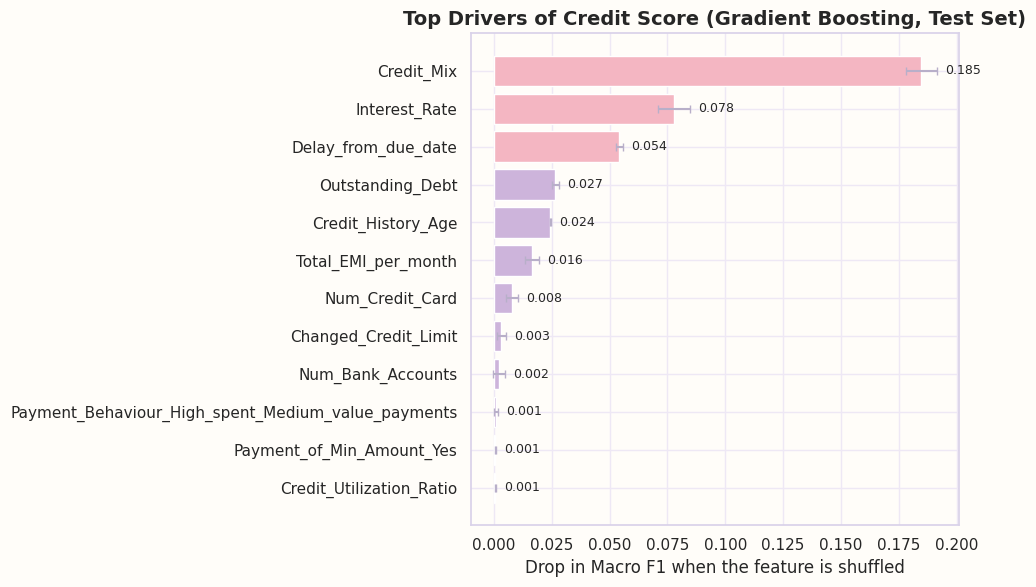

🔹 TOP 8 FEATURES


,Feature,Importance,Std
0,Credit_Mix,0.185,0.007
1,Interest_Rate,0.078,0.007
2,Delay_from_due_date,0.054,0.001
3,Outstanding_Debt,0.027,0.002
4,Credit_History_Age,0.024,0.000
5,Total_EMI_per_month,0.016,0.003
6,Num_Credit_Card,0.008,0.003
7,Changed_Credit_Limit,0.003,0.002


In [95]:
# ===== 30. CHART 10: FEATURE IMPORTANCE (PERMUTATION IMPORTANCE) =====

# Needs from earlier cells: final_model, best_name, X_test, y_test, PASTEL
from sklearn.inspection import permutation_importance

def get_importance(model, X, y, n_rows=3000, repeats=3, seed=42):
    """Shuffles one column at a time and measures how much Macro F1 drops. Bigger drop = more important.
    Uses a random sample of test rows so it stays fast."""
    Xs = X.sample(min(n_rows, len(X)), random_state=seed)
    ys = y.loc[Xs.index]
    result = permutation_importance(model, Xs, ys, scoring="f1_macro",
                                    n_repeats=repeats, random_state=seed)
    return (pd.DataFrame({"Feature": X.columns,
                          "Importance": result.importances_mean,
                          "Std": result.importances_std})
            .sort_values("Importance", ascending=False).reset_index(drop=True))

def plot_importance(imp, top_n=12, title=""):
    """Pastel horizontal bar chart of the top features (top 3 in pink)."""
    top = imp.head(top_n)[::-1]                      # reverse so the biggest bar is on top
    colors = [PASTEL["lavender"]] * len(top)
    for i in range(1, min(3, len(top)) + 1):         # last 3 bars = top 3 drivers
        colors[-i] = PASTEL["pink"]
    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(top["Feature"], top["Importance"], xerr=top["Std"], color=colors,
                   edgecolor="white", error_kw={"ecolor": "#B8AFC9", "capsize": 3})
    ax.bar_label(bars, fmt="%.3f", padding=6, fontsize=9)   # label the bars, not the error bars
    ax.set_xlabel("Drop in Macro F1 when the feature is shuffled")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

print(f"⏳ Calculating importance for {best_name} (about 10 to 40 seconds)...\n")
importance = get_importance(final_model, X_test, y_test)
plot_importance(importance, title=f"Top Drivers of Credit Score ({best_name}, Test Set)")

print("🔹 TOP 8 FEATURES")
display(importance.head(8).style.format({"Importance": "{:.3f}", "Std": "{:.3f}"})
        .background_gradient(cmap="BuPu", subset=["Importance"]))

### Chart 10: Feature Importance (what drives the prediction?)
**Why this chart?** Permutation importance shuffles one column at a time and checks how much the model's Macro F1 drops. A big drop means the model relies on that column. It works on unseen test data, so it shows what the model truly uses.

**Insight:** The top drivers are **Credit_Mix**, **Interest_Rate** and **Delay_from_due_date**. In business words:
- **Credit mix (importance 0.185):** by far the strongest driver. Customers with a healthier mix of credit types tend to have better scores.
- **Interest rate (0.078):** higher interest rates go with weaker scores.
- **Days late on payments (0.054):** customers who pay late are more likely to be Poor.
- **Outstanding debt (0.027) and credit history length (0.024):** smaller but real signals. More debt and a shorter history go with weaker scores.
- Features such as Num_Credit_Card and Changed_Credit_Limit add very little.

**Business impact:** Paisabazaar can focus on a few strong signals: credit mix, interest rate and payment behaviour. It can also give customers simple advice, such as "pay on time" and "reduce outstanding debt". **Caution:** this shows what the model uses, not what causes a score. Features that carry similar information share the credit, so each one can look smaller than it is. Credit_Mix is also a very strong signal, so checking how it is measured would be useful future work.

## Business Impact
### How Paisabazaar can use this model
- **Quick pre-screening:** score applicants as Poor, Standard or Good before the detailed check, so loan officers spend time where it matters.
- **Risk-based decisions:** approve Good customers faster, send Standard customers for a manual review, and look closely at Poor customers.
- **Product matching:** show Good customers better cards and loans. Show Poor customers credit-builder products.
- **Personal advice:** use the top drivers to tell customers what to improve (pay on time, lower debt).

### The cost of being wrong
| Mistake | What it means | Cost |
|---------|---------------|------|
| Poor called Good | A risky customer gets approved | **Highest.** Possible loan default and lost money. |
| Good called Poor | A safe customer is turned away | Medium. Lost business and a unhappy customer. |
| Standard mixed with a neighbour | A borderline case is misjudged | Low to medium. A manual review can catch it. |

This is why we chose the final model using **Macro F1 and Poor recall**, not accuracy alone.

### Limits (be honest about them)
- The model is **not 100% accurate**, so it should **support** people, not replace them. Keep a human check for important decisions.
- Each customer appears **8 times** in the data, so the effective number of customers is 12,500, not 100,000.
- Some records have **under-18 ages** and **hidden missing values** ("NM", "No Data"). We handled them, but they add uncertainty.
- Credit scores **change month to month**, so the model needs regular retraining.
- The data may not match future customers. Check for bias and fairness before real use.

In [96]:
# ===== 31. SAVE THE FINAL MODEL, RELOAD IT AND CHECK (JOBLIB) =====

# Needs from earlier cells: final_model, best_name, X_test, y_test
import joblib, os

MODEL_FILE = "/content/final_credit_model.joblib"
LABELS = {0: "Poor", 1: "Standard", 2: "Good"}

def save_model(model, feature_names, path):
    """Saves the model together with its column names and label meanings in one file."""
    joblib.dump({"model": model, "features": list(feature_names), "labels": LABELS}, path)
    print(f"✅ Model saved: {path} ({os.path.getsize(path) / 1e6:.1f} MB)")

def load_model(path):
    """Loads the saved file and returns the model bundle."""
    bundle = joblib.load(path)
    print("✅ Model loaded back from file")
    return bundle

def predict_scores(bundle, rows):
    """Predicts with a loaded model bundle. Columns are put in the same order as in training."""
    X_new = rows[bundle["features"]]
    return bundle["model"].predict(X_new), bundle["model"].predict_proba(X_new)

# 1. Save, then reload
print(f"🔹 SAVING: {best_name}\n")
save_model(final_model, X_test.columns, MODEL_FILE)
loaded = load_model(MODEL_FILE)

# 2. Sanity check on 5 unseen test rows
sample_rows = X_test.sample(5, random_state=7)
true_labels = y_test.loc[sample_rows.index]

pred_original = final_model.predict(sample_rows)
proba_original = final_model.predict_proba(sample_rows)
pred_loaded, proba_loaded = predict_scores(loaded, sample_rows)

check = pd.DataFrame({
    "Actual": true_labels.map(LABELS).values,
    "Predicted (original)": pd.Series(pred_original).map(LABELS).values,
    "Predicted (reloaded)": pd.Series(pred_loaded).map(LABELS).values,
    "Confidence": proba_loaded.max(axis=1)})
print("\n🔹 5 UNSEEN ROWS")
display(check.style.format({"Confidence": "{:.0%}"}))

# 3. The reloaded model must give exactly the same answers
same_labels = np.array_equal(pred_original, pred_loaded)
same_probs = np.allclose(proba_original, proba_loaded)
print(f"\n🔒 Same predicted labels:        {same_labels}")
print(f"🔒 Same predicted probabilities: {same_probs}")
print("✅ SANITY CHECK PASSED" if same_labels and same_probs else "❌ MISMATCH: do not use this file")

print("\n📥 To download the file: click the folder icon on the left of Colab,")
print("   find 'final_credit_model.joblib', click the 3 dots and choose Download.")
print("   (Colab deletes files when the session ends, so download it before you close.)")

🔹 SAVING: Gradient Boosting

✅ Model saved: /content/final_credit_model.joblib (3.3 MB)
✅ Model loaded back from file

🔹 5 UNSEEN ROWS


,Actual,Predicted (original),Predicted (reloaded),Confidence
0,Standard,Standard,Standard,70%
1,Standard,Good,Good,53%
2,Poor,Standard,Standard,58%
3,Standard,Standard,Standard,70%
4,Poor,Standard,Standard,82%



🔒 Same predicted labels:        True
🔒 Same predicted probabilities: True
✅ SANITY CHECK PASSED

📥 To download the file: click the folder icon on the left of Colab,
   find 'final_credit_model.joblib', click the 3 dots and choose Download.
   (Colab deletes files when the session ends, so download it before you close.)


## Future Work
- **Saved model:** the final model is saved as `final_credit_model.joblib`. It can be reloaded and used in any Python app (for example a simple web form for loan officers).
- **Regular retraining:** credit scores change from month to month, so retrain the model on new data every few months.
- **Better features:** add each customer's history across months, such as the trend in late payments.
- **Choose the risk level:** change the decision rule so more Poor customers are caught, if the business accepts more manual checks.
- **Fairness check:** test whether the model treats age groups fairly, since under-18 records exist in the data.
- **Fraud and monitoring:** track the model after launch, and raise an alert if its accuracy drops.

## Final Conclusion

### Key findings
- **Data:** 100,000 rows, 12,500 customers, 8 months each. No NaN values, but missing data was hidden as "NM" and "No Data".
- **Classes:** 53% Standard, 29% Poor, 18% Good, so the data is imbalanced.
- **Age:** under-18 customers are 45% Poor, ages 18 to 45 about 31%, and 46+ only 12.6%. Occupation barely matters.
- **Statistics:** payment delay, credit mix and interest rate are all significantly linked to credit score (3 tests, all supported).
- **Model:** tree models clearly beat Logistic Regression, so the link between features and score is not a straight line.
- **Final model:** **Gradient Boosting**, with **68.7% accuracy, 68.1% macro F1 and 76.3% Poor recall** on unseen customers. Random Forest caught slightly more Poor customers (78.1%) but had lower macro F1 (67.2%).
- **Main drivers:** **Credit_Mix, Interest_Rate and Delay_from_due_date**.
- **Weak spots:** about 10.8% of Poor customers are called Good, and only about 53% of customers called Good really are Good.

### Business recommendations
1. Use the model to **pre-screen** applicants, and keep a human check for important decisions.
2. Send borderline cases and big loan requests for **manual review**, especially customers the model calls Good.
3. Treat **Poor called Good** as the costliest mistake, so keep watching Poor recall.
4. Give customers simple advice from the top drivers (pay on time, lower debt, keep a healthy credit mix).
5. Match products to risk level: better offers for Good, credit-builder products for Poor.

### Limitations
- Only **8 rows per customer**, so the effective sample is 12,500 customers.
- **Under-18 records** exist and look unusual.
- **Hidden missing values** ("NM", "No Data") add uncertainty.
- Credit scores **change month to month**, so the model gets out of date.
- The model is not perfect (about 69% accuracy) and may carry bias, so check fairness before real use.

### Future work
Retrain regularly, add month-by-month trend features, test fairness across age groups, tune the decision rule for higher Poor recall, check how Credit_Mix is measured, and serve the saved `.joblib` model in a simple app.